# Charts and search

Queries the `birds` MySQL database (run `python pipeline.py` first) using the files in `sql/queries/`.

In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import db

con = db.connect()


def run_query_file(name) -> pd.DataFrame:
    """Run a file from sql/queries/ and return its result as a DataFrame."""
    result = db.run_sql_file(con, ROOT / "sql" / "queries" / name)
    if result is None:
        raise ValueError(f"{name} has no query that returns rows")
    return result


def query(sql) -> pd.DataFrame:
    """Run a query and return its result as a DataFrame."""
    return db.query(con, sql)

## Search

To change the filters edit the `SET` lines at the top of `sql/queries/search.sql`.

In [10]:
results = run_query_file("search.sql")
for bird in results.itertuples():
    print(f"Scientific Name: {bird.scientific_name}")
    print(f"Common Name: {bird.common_name}")
    print(f"Group Category: {bird.group_category}")
    print(f"Order: {bird.order_name}")
    print(f"Family: {bird.family_name}")
    print(f"Conservation Status: {bird.conservation_status}")
    print(f"Location: {bird.locations}")
    print("-" * 100)
print(f"{len(results)} species match")

Scientific Name: ANSER CANAGICA
Common Name: EMPEROR GOOSE
Group Category: DUCKS, GEESE, WATERFOWL
Order: ANSERIFORMES
Family: ANATIDAE
Conservation Status: NEAR THREATENED
Location: Alaska, California, Hawaii, Idaho, Nebraska, Oregon, Texas, Washington
----------------------------------------------------------------------------------------------------
Scientific Name: ANSER CAERULESCENS
Common Name: SNOW GOOSE
Group Category: DUCKS, GEESE, WATERFOWL
Order: ANSERIFORMES
Family: ANATIDAE
Conservation Status: LEAST CONCERN
Location: Alabama, Alaska, Arizona, Arkansas, California, Colorado, Connecticut, Delaware, Florida, Georgia, Hawaii, Idaho, Illinois, Indiana, Iowa, Kansas, Kentucky, Louisiana, Maine, Maryland, Massachusetts, Michigan, Minnesota, Mississippi, Missouri, Montana, Nebraska, Nevada, New Hampshire, New Jersey, New Mexico, New York, North Carolina, North Dakota, Ohio, Oklahoma, Oregon, Pennsylvania, Rhode Island, South Carolina, South Dakota, Tennessee, Texas, Utah, Vermont

## All species

One row per species from the `species_detail` view.

In [11]:
df = query("""
SELECT common_name, scientific_name, group_category, order_name, family_name, conservation_status, locations
FROM species_detail
ORDER BY list_order
""")
df.head()

,common_name,scientific_name,group_category,order_name,family_name,conservation_status,locations
0,WHITE-FACED WHISTLING-DUCK,DENDROCYGNA VIDUATA,"DUCKS, GEESE, WATERFOWL",ANSERIFORMES,ANATIDAE,LEAST CONCERN,"Florida, Texas"
1,BLACK-BELLIED WHISTLING-DUCK,DENDROCYGNA AUTUMNALIS,"DUCKS, GEESE, WATERFOWL",ANSERIFORMES,ANATIDAE,LEAST CONCERN,"Alabama, Arizona, Arkansas, California, Colora..."
2,WEST INDIAN WHISTLING-DUCK,DENDROCYGNA ARBOREA,"DUCKS, GEESE, WATERFOWL",ANSERIFORMES,ANATIDAE,NEAR THREATENED,"Florida, Texas, Virginia"
3,FULVOUS WHISTLING-DUCK,DENDROCYGNA BICOLOR,"DUCKS, GEESE, WATERFOWL",ANSERIFORMES,ANATIDAE,LEAST CONCERN,"Alabama, Arizona, Arkansas, California, Colora..."
4,EMPEROR GOOSE,ANSER CANAGICA,"DUCKS, GEESE, WATERFOWL",ANSERIFORMES,ANATIDAE,NEAR THREATENED,"Alaska, California, Hawaii, Idaho, Nebraska, O..."


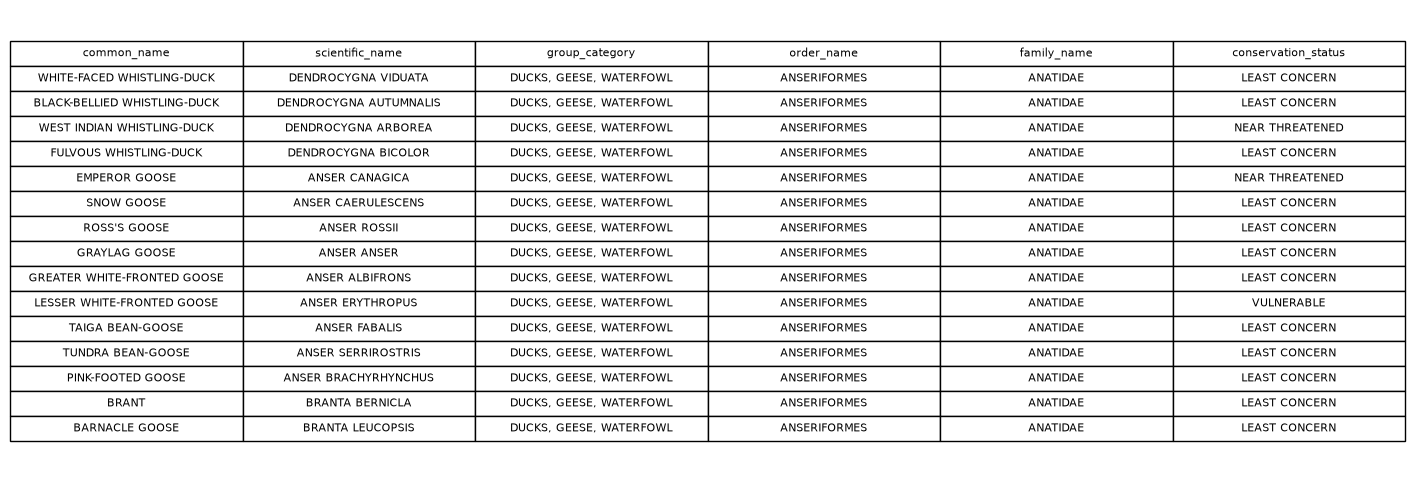

In [12]:
df_without_location = df.drop(columns=["locations"]).head(15)
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")
table = ax.table(cellText=df_without_location.astype(str).values.tolist(), colLabels=list(df_without_location.columns), loc="center", cellLoc="center")
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1.5, 1.5)
plt.show()

## Species per conservation status

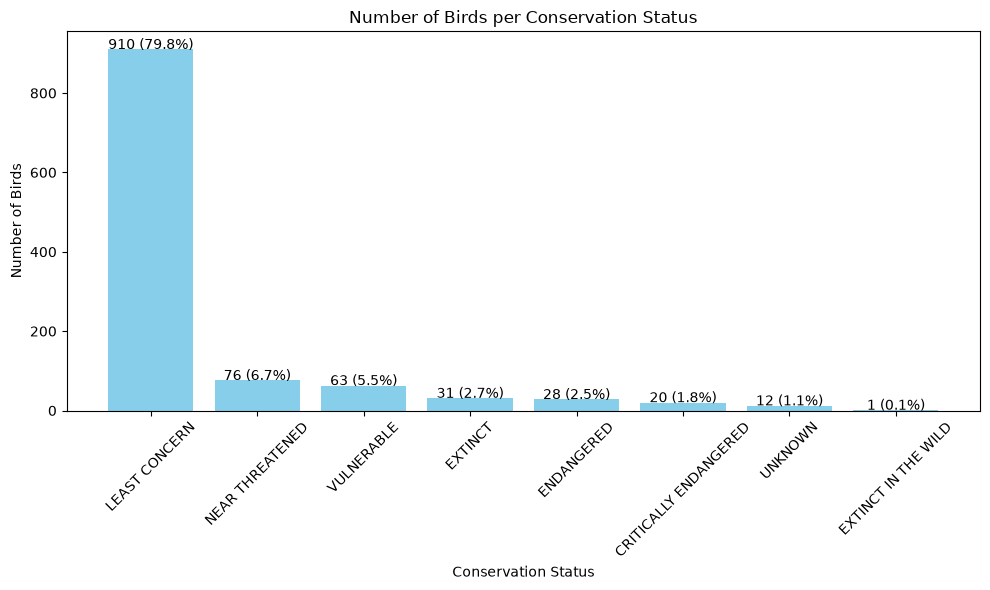

,status_name,n_species,pct_of_species
0,LEAST CONCERN,910,79.8
1,NEAR THREATENED,76,6.7
2,VULNERABLE,63,5.5
3,EXTINCT,31,2.7
4,ENDANGERED,28,2.5
5,CRITICALLY ENDANGERED,20,1.8
6,UNKNOWN,12,1.1
7,EXTINCT IN THE WILD,1,0.1


In [13]:
status_counts = run_query_file("status_counts.sql")

plt.figure(figsize=(10, 6))
plt.bar(status_counts["status_name"], status_counts["n_species"], color="skyblue")
for i, (n_species, pct) in enumerate(zip(status_counts["n_species"], status_counts["pct_of_species"])):
    plt.text(i, n_species + 1, f"{n_species} ({pct:.1f}%)", ha="center", fontsize=10)
plt.title("Number of Birds per Conservation Status")
plt.xlabel("Conservation Status")
plt.ylabel("Number of Birds")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
status_counts

## Conservation status by state

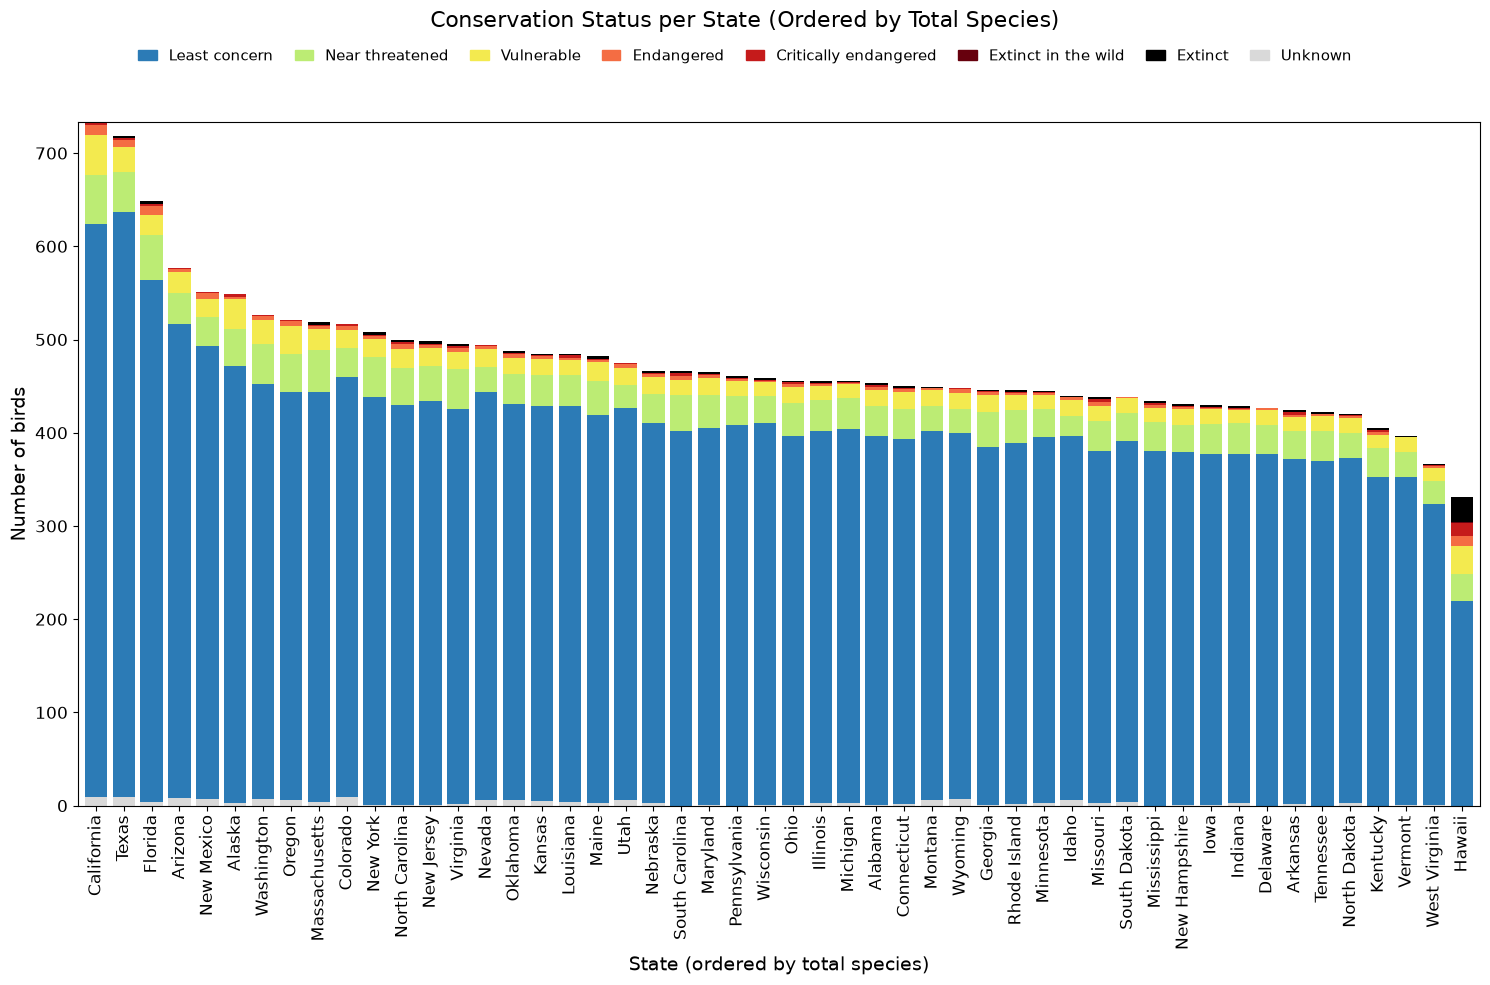

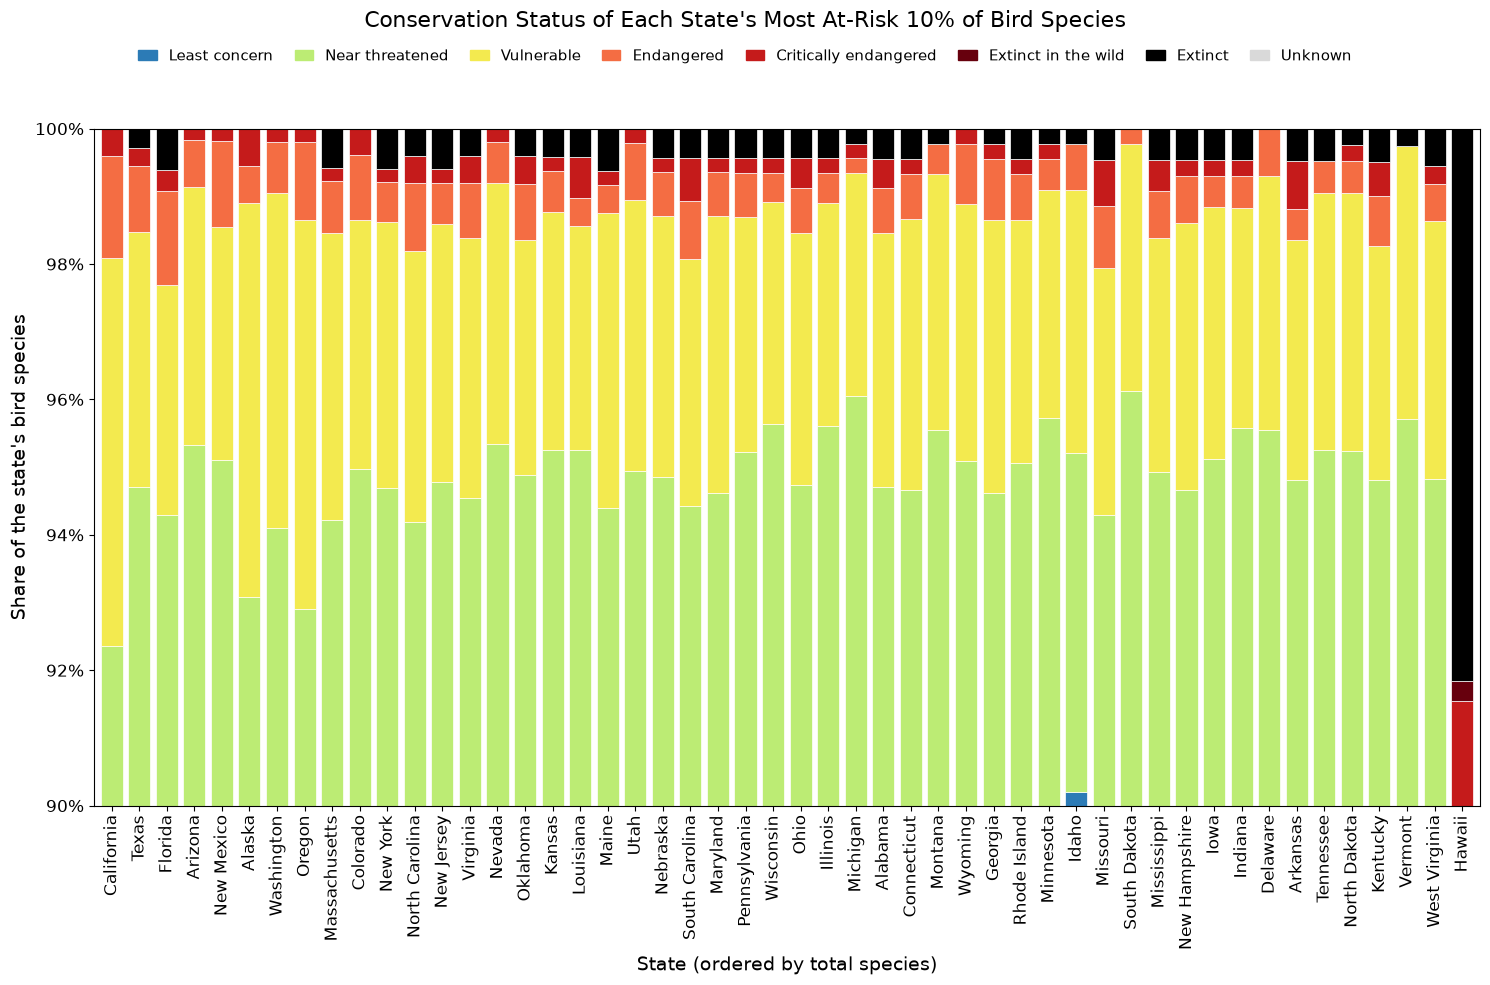

In [14]:
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

status_by_state = run_query_file("status_by_state.sql").set_index("state_name")
status_order = query("SELECT status_name FROM conservation_status ORDER BY chart_order")["status_name"].tolist()

color_palette = {
    "UNKNOWN": "#d9d9d9",
    "LEAST CONCERN": "#2c7bb6",
    "NEAR THREATENED": "#bcec74",
    "VULNERABLE": "#f3ea4f",
    "ENDANGERED": "#f46d43",
    "CRITICALLY ENDANGERED": "#c51b1b",
    "EXTINCT IN THE WILD": "#67000d",
    "EXTINCT": "#000000",
}
key_order = [s for s in status_order if s != "UNKNOWN"] + ["UNKNOWN"]


def plot_status_by_state(data, title, ylabel, ylim=None, percent=False):
    """Stacked bar per state with the key above the chart."""
    fig, ax = plt.subplots(figsize=(15, 10))
    data[status_order].plot(kind="bar", stacked=True, ax=ax, width=0.8, legend=False,
                            color=[color_palette[s] for s in status_order],
                            edgecolor="white", linewidth=0.5 if percent else 0)
    if ylim:
        ax.set_ylim(*ylim)
    if percent:
        ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))

    ax.set_ylabel(ylabel, fontsize=14)
    ax.set_xlabel("State (ordered by total species)", fontsize=14)
    ax.tick_params(axis="x", labelrotation=90, labelsize=12)
    ax.tick_params(axis="y", labelsize=12)
    fig.suptitle(title, fontsize=16)
    fig.legend(handles=[Patch(color=color_palette[s], label=s.capitalize()) for s in key_order],
               loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=len(key_order), fontsize=11,
               frameon=False, handlelength=1.2, columnspacing=1.4)
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    plt.show()


# Full view shows number of species per status
plot_status_by_state(status_by_state, "Conservation Status per State (Ordered by Total Species)", "Number of birds")

# Zoomed view which shows the top ZOOM percent of each bar.
# The most severe statuses sit at the top, so this is each state's most at risk species percentages.
ZOOM = 10
shares = status_by_state[status_order].div(status_by_state["total_species"], axis=0) * 100
plot_status_by_state(shares, f"Conservation Status of Each State's Most At-Risk {ZOOM}% of Bird Species",
                     "Share of the state's bird species", ylim=(100 - ZOOM, 100), percent=True)

In [15]:
from IPython.display import display

summary = run_query_file("state_summary.sql").set_index("state_name")

# Measures to show in display order with their row labels
labels = {
    "species_rank": "Rank by species count (of 50)",
    "total_species": "Total species",
    "pct_of_us_species": "Share of all U.S. species",
    "least_concern": "Least concern",
    "near_threatened": "Near threatened",
    "threatened": "Threatened (vulnerable, endangered, critically endangered)",
    "critically_endangered": "  of which critically endangered",
    "extinct": "Extinct or extinct in the wild",
    "unknown_status": "Unknown status",
    "pct_least_concern": "Share least concern",
    "pct_threatened": "Share threatened",
    "pct_at_risk": "Share at risk (threatened or extinct)",
    "risk_rank": "At-risk rank (1 = lowest share)",
    "only_in_state": "Species recorded in no other state",
    "families": "Bird families",
    "orders": "Bird orders",
}


def fmt(measure, value):
    """Percentages with one decimal and a % sign, and counts and ranks as whole numbers."""
    return f"{value:.1f}%" if measure.startswith("pct_") else f"{int(value):,}"


def state_table(states, difference=False) -> pd.DataFrame:
    """The given states side by side with one row per measure."""
    table = summary.loc[states, list(labels)].T
    if difference:
        table["Difference"] = table.iloc[:, 1] - table.iloc[:, 0]
    formatted = table.astype(object)
    for measure in table.index:
        formatted.loc[measure] = [fmt(str(measure), value) for value in table.loc[measure]]
    return formatted.rename(index=labels)


states_by_size = summary.index.tolist()  # the query orders states by total species
print("Top 3 states by number of species")
display(state_table(states_by_size[:3]))
print("Bottom 3 states by number of species")
display(state_table(states_by_size[-3:]))

# Best = lowest share of species that are threatened or extinct, worst = highest
by_risk = summary.sort_values("risk_rank")
best, worst = by_risk.index[0], by_risk.index[-1]
print(f"Best vs. worst state: {best} has the lowest share of species at risk "
      f"({summary.loc[best, 'pct_at_risk']:.1f}% of {summary.loc[best, 'total_species']:,}), "
      f"{worst} the highest ({summary.loc[worst, 'pct_at_risk']:.1f}% of {summary.loc[worst, 'total_species']:,})")
comparison = state_table([best, worst], difference=True)
comparison.columns = [f"Best: {best}", f"Worst: {worst}", "Difference (worst - best)"]
display(comparison)

Top 3 states by number of species


state_name,California,Texas,Florida
Rank by species count (of 50),1,2,3
Total species,733,718,649
Share of all U.S. species,64.2%,62.9%,56.9%
Least concern,615,628,560
Near threatened,53,43,48
"Threatened (vulnerable, endangered, critically endangered)",56,36,33
of which critically endangered,3,2,2
Extinct or extinct in the wild,0,2,4
Unknown status,9,9,4
Share least concern,83.9%,87.5%,86.3%


Bottom 3 states by number of species


state_name,Vermont,West Virginia,Hawaii
Rank by species count (of 50),48,49,50
Total species,396,367,331
Share of all U.S. species,34.7%,32.2%,29.0%
Least concern,352,323,220
Near threatened,26,24,28
"Threatened (vulnerable, endangered, critically endangered)",16,17,55
of which critically endangered,0,1,14
Extinct or extinct in the wild,1,2,28
Unknown status,1,1,0
Share least concern,88.9%,88.0%,66.5%


Best vs. worst state: South Dakota has the lowest share of species at risk (3.9% of 438), Hawaii the highest (25.1% of 331)


,Best: South Dakota,Worst: Hawaii,Difference (worst - best)
Rank by species count (of 50),37,50,13
Total species,438,331,-107
Share of all U.S. species,38.4%,29.0%,-9.4%
Least concern,387,220,-167
Near threatened,30,28,-2
"Threatened (vulnerable, endangered, critically endangered)",17,55,38
of which critically endangered,0,14,14
Extinct or extinct in the wild,0,28,28
Unknown status,4,0,-4
Share least concern,88.4%,66.5%,-21.9%


## Close the connection

In [16]:
con.close()